# Some notes on the project

## Start simple: let's segment some of the data

### Calling the data

In [1]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "data/earndb_average"
records = {
    "N1": {"R1": "N1_evoked_ave100_F1_R1", "R2": "N1_evoked_ave100_F1_R2"},
    "N2": {"R1": "N2_evoked_ave100_F1_R1", "R2": "N2_evoked_ave100_F1_R2"},
}

signals = {
    subj: {rep: wfdb.rdrecord(f"{DATA_DIR}/{name}") for rep, name in reps.items()}
    for subj, reps in records.items()
}

# sanity check: signal names and sampling rate
for subj, reps in signals.items():
    for rep, rec in reps.items():
        print(f'subject = {subj}, rep = {rep}, signal type = {rec.sig_name[0]}, frequency = {int(rec.fs/1000)} kHz, time series = {rec.p_signal.shape[0]}')

subject = N1, rep = R1, signal type = ABR, frequency = 48 kHz, time series = 2002
subject = N1, rep = R2, signal type = ABR, frequency = 48 kHz, time series = 2002
subject = N2, rep = R1, signal type = ABR, frequency = 48 kHz, time series = 2002
subject = N2, rep = R2, signal type = ABR, frequency = 48 kHz, time series = 2002


### Plotting the data

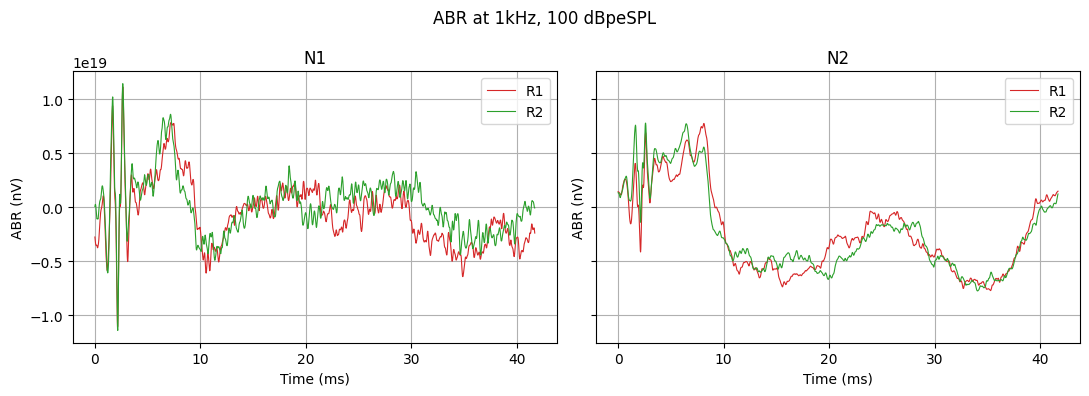

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

colors = {"R1": "tab:red", "R2": "tab:green"}

for ax, (subj, reps) in zip(ax, signals.items()):
    for rep, rec in reps.items():
        t_ms = np.arange(rec.p_signal.shape[0]) / rec.fs * 1000  # samples -> ms
        abr_idx = rec.sig_name.index("ABR")
        ax.plot(t_ms, rec.p_signal[:, abr_idx], linewidth=0.8,
                 color=colors[rep], label=rep)

    ax.set_title(subj)
    ax.grid(True)
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel(f"ABR ({rec.units[abr_idx]})")
    ax.legend()

fig.suptitle("ABR at 1kHz, 100 dBpeSPL")
fig.tight_layout()
plt.show()

## Download all data

In [7]:
"""Download only raw ABR signals and their calibration headers."""

from pathlib import Path, PurePosixPath
import time
from urllib.request import urlopen

BASE = "https://physionet.org/files/earndb/1.0.0/"

OUTPUT_FOLDER = Path(
    r"C:\\Users\borra\\OneDrive\\Masaüstü\\Hearing research\\Coding\\Physio-ABR-Data"
)

# None downloads all records. Set to 1 to test one record.
RECORD_LIMIT = None


def fetch(path):
    with urlopen(BASE + path, timeout=120) as response:
        return response.read()


def download_record(record, destination):
    lines = fetch(record + ".hea").decode("ascii").splitlines()
    first = lines[0].split()
    count, samples = int(first[1]), int(first[3])

    signals = [line.split() for line in lines[1:count + 1]]
    abr = [
        i for i, signal in enumerate(signals)
        if signal[2].split("/")[-1] == "nV"
    ]

    if not abr:
        return "OAE only; skipped"

    if len(abr) != 1:
        raise ValueError("Expected exactly one ABR channel")

    index = abr[0]
    fmt = signals[index][1]

    if fmt not in {"16", "24", "32"} or any(
        s[0] != signals[index][0] or s[1] != fmt
        for s in signals
    ):
        raise ValueError(
            "Unsupported signal layout; refusing to alter samples"
        )

    width = int(fmt) // 8
    folder = destination / PurePosixPath(record).parent
    folder.mkdir(parents=True, exist_ok=True)

    name = PurePosixPath(record).name
    dat = folder / (name + ".dat")
    hea = folder / (name + ".hea")

    if (
        hea.exists()
        and dat.exists()
        and dat.stat().st_size == samples * width
    ):
        return "already complete"

    source = str(
        PurePosixPath(record).parent / signals[index][0]
    )
    temporary = dat.with_suffix(".dat.part")

    frame_size = count * width
    written = 0
    pending = b""

    with (
        urlopen(BASE + source, timeout=120) as response,
        temporary.open("wb") as output,
    ):
        while True:
            chunk = response.read(1024 * 1024)

            if not chunk:
                break

            pending += chunk
            length = len(pending) // frame_size * frame_size
            block, pending = pending[:length], pending[length:]

            # Preserve the original ABR integer samples exactly.
            extracted = bytearray(length // count)

            for byte in range(width):
                extracted[byte::width] = block[
                    index * width + byte::frame_size
                ]

            output.write(extracted)
            written += len(extracted)

    if pending or written != samples * width:
        raise ValueError(
            "Incomplete or unexpected signal length; rerun to retry"
        )

    first[1] = "1"
    signal = signals[index][:]
    signal[0] = dat.name

    header = "\n".join(
        [" ".join(first), " ".join(signal)]
        + lines[count + 1:]
    ) + "\n"

    temporary.replace(dat)
    hea.write_text(header, encoding="ascii")

    return f"saved ABR ({written:,} bytes)"


def download_all():
    if RECORD_LIMIT is not None and RECORD_LIMIT < 1:
        raise ValueError("RECORD_LIMIT must be None or a positive integer")

    OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
    print(f"Destination: {OUTPUT_FOLDER}", flush=True)
    print("Fetching record list...", flush=True)

    records = [
        r.strip()
        for r in fetch("RECORDS").decode("ascii").splitlines()
        if r.strip().startswith("raw/")
    ]

    if not records:
        raise RuntimeError("No raw records found in the dataset index")

    if RECORD_LIMIT is not None:
        records = records[:RECORD_LIMIT]

    print(f"Raw records to inspect: {len(records)}", flush=True)

    failures = []
    started = time.monotonic()

    for number, record in enumerate(records, 1):
        print(
            f"[{number}/{len(records)}] Processing {record}",
            flush=True,
        )

        for attempt in range(3):
            try:
                status = download_record(record, OUTPUT_FOLDER)
                print(f"    {status}", flush=True)
                break

            except Exception as error:
                if attempt == 2:
                    failures.append(record)
                    print(f"    FAILED: {error}", flush=True)
                else:
                    print(
                        f"    Retrying after error: {error}",
                        flush=True,
                    )
                    time.sleep(2 * (attempt + 1))

    elapsed_minutes = (time.monotonic() - started) / 60

    if failures:
        print(
            f"\nFinished with {len(failures)} failed records "
            f"after {elapsed_minutes:.1f} minutes.",
            flush=True,
        )
        print(
            "Run this cell again to retry. Completed records are skipped.",
            flush=True,
        )
    else:
        print(
            "\nDone. Only raw ABR signals and their "
            "calibration headers were saved.",
            flush=True,
        )
        print(f"Elapsed time: {elapsed_minutes:.1f} minutes.", flush=True)

    return failures


failed_records = download_all()

Destination: C:\Users\borra\OneDrive\Masaüstü\Hearing research\Coding\Physio-ABR-Data
Fetching record list...
Raw records to inspect: 2087
[1/2087] Processing raw/N1/N1_evoked_raw_100_F1_R1
    already complete
[2/2087] Processing raw/N1/N1_evoked_raw_100_F1_R2
    already complete
[3/2087] Processing raw/N1/N1_evoked_raw_100_F1_R3
    already complete
[4/2087] Processing raw/N1/N1_evoked_raw_100_F4_R1
    already complete
[5/2087] Processing raw/N1/N1_evoked_raw_100_F4_R2
    already complete
[6/2087] Processing raw/N1/N1_evoked_raw_100_F4_R3_x
    already complete
[7/2087] Processing raw/N1/N1_evoked_raw_100_F4_R4
    already complete
[8/2087] Processing raw/N1/N1_evoked_raw_100_F4_R5
    already complete
[9/2087] Processing raw/N1/N1_evoked_raw_100_F4_R6
    already complete
[10/2087] Processing raw/N1/N1_evoked_raw_100_F4_R7_x
    already complete
[11/2087] Processing raw/N1/N1_evoked_raw_100_F4_R8
    already complete
[12/2087] Processing raw/N1/N1_evoked_raw_10_F1_R1
    already 

## fmpi analysis time

### step 1: data structure